# B · Tokens by rank

[Figure 3 index](../README.md#figure-3) · [Complete
assembly](figure3_assembly.ipynb#complete-figure-3).

Figure 3B shows how mean tokens sent and received vary with the Social
Rank GAP. Its input is `data/generated/main/analysis_dyads.csv`,
prepared in [Data and measures](01_data_and_measures.ipynb). The three
relationship groups are non-friends, mutual friends, and sender-declared
one-sided friendships.

# Step 1. Summarize each child and relationship group

Every child counts once within each friendship group. `gap` is the
median of that child’s dyadic `rank_gap` values. `sent` and `received`
are the child’s mean transfers; `dif_coop` is `received - sent`. These
are child-level summaries, rather than new names for the
directed-decision variables.

In [ ]:
here::i_am("notebooks/main/06_figure3b_tokens_by_rank.qmd")
library(tidyverse)
library(here)
source(here("code", "00_style.R"))

The data are reused if `analysis_dyads` and `analysis_students` are
already in R. Otherwise, this step loads their CSV files from
`data/generated/main/`, or builds them from the raw inputs on first use.

In [ ]:
source(here("code", "00_load_main_data.R"), local = TRUE)
dyads <- analysis_dyads

In [ ]:
main_data_status

dataset,rows,source
analysis_dyads,17804,Saved CSV files
analysis_students,859,Saved CSV files


The next chunks build auxiliary tables for panel B from
`analysis_dyads`. `summary_by_child()` calculates the values collected
in `children`, and `summary_by_bin()` summarizes them into `binned`. The
plotting function uses `binned` for the coordinates, means, and
intervals.

In [ ]:
# Panels B and C summarize transfers in two aggregation stages:
#
#   1. Summary by child. For each child (sender) and friendship group: her
#      mean tokens sent, her mean tokens received, her Cooperation GAP as the
#      difference between those two means (received - sent), and the median
#      Social Rank GAP of those partners. With observed transfers, panel C
#      equals the distance between the two mean curves of panel B.
#   2. Bins. The median rank gaps of the group are split into 7 intervals of
#      equal width ("round_gap"). The bins use all the children of the group,
#      so the observed and the filtered versions share the same bins.
#   3. Table of means by bin. Across the children of each bin: the mean and
#      SD of each measure, the position of the bin (mean of the children's
#      median gaps) and a 95% interval, mean +/- 1.96 * SD / sqrt(n), with n
#      the number of children in the bin.
#   4. The panels draw that table.
#
# Filtered version: a transfer dropped by the null-model filter is NA.
# Each direction keeps all of its retained transfers:
# the child's mean filtered tokens received minus her mean filtered tokens
# sent. (The filtered regressions, instead, use only pairs with both
# directions retained.) Children with nothing retained in one of the two
# directions have no filtered GAP; they stay in the total bin count n, and
# `n_with_value` counts finite child GAPs. The filtered sent, received, and GAP
# means can use different valid-child sets, so their bin-level difference
# need not equal the filtered GAP curve.

summary_by_child <- function(data, sent, received) {
  data %>%
    group_by(sender_id) %>%
    summarise(gap      = median(rank_gap),
              sent     = mean({{ sent }}, na.rm = TRUE),
              received = mean({{ received }}, na.rm = TRUE),
              .groups  = "drop") %>%
    mutate(dif_coop = received - sent)
}

summary_by_bin <- function(children, coef = 1.96, n_bins = 7) {
  children %>%
    mutate(round_gap = cut_interval(gap, n_bins, dig.lab = 1)) %>%
    group_by(round_gap) %>%
    summarise(median_gap    = mean(gap),     # position of the bin on the x axis
              n             = n(),
              n_with_value  = sum(is.finite(dif_coop)),
              mean_sent     = mean(sent, na.rm = TRUE),
              sd_sent       = sd(sent, na.rm = TRUE),
              mean_reci     = mean(received, na.rm = TRUE),
              sd_reci       = sd(received, na.rm = TRUE),
              mean_dif_coop = mean(dif_coop, na.rm = TRUE),
              sd_dif_coop   = sd(dif_coop, na.rm = TRUE),
              .groups = "drop") %>%
    mutate(se_sent     = coef * sd_sent / sqrt(n),
           se_reci     = coef * sd_reci / sqrt(n),
           se_dif_coop = coef * sd_dif_coop / sqrt(n))
}

rank_groups <- c("Non-friends", "Mutual", "Sender declares")

In [ ]:
# Step 1, for every friendship group, with observed and with filtered tokens
children <- map_dfr(rank_groups, function(this_group) {
  group_data <- dyads %>% filter(friendship == this_group)
  bind_rows(
    summary_by_child(group_data, tokens_sent, tokens_received) %>% mutate(version = "Observed"),
    summary_by_child(group_data, tokens_sent_filtered, tokens_received_filtered) %>% mutate(version = "Filtered")
  ) %>%
    mutate(group = this_group)
})

# a few children of the non-friends group, filtered tokens
children %>% filter(group == "Non-friends", version == "Filtered") %>% head()

In [ ]:
children %>% filter(group == "Non-friends", version == "Observed") %>% head()

sender_id,gap,sent,received,dif_coop,version,group
1,0.0737360,2.000000,3.083333,1.083333,Observed,Non-friends
2,-0.1352346,8.700000,4.500000,-4.200000,Observed,Non-friends
3,0.5987818,1.750000,3.300000,1.550000,Observed,Non-friends
4,-0.3131235,4.625000,3.562500,-1.062500,Observed,Non-friends
5,0.2103567,7.307692,4.692308,-2.615385,Observed,Non-friends
6,0.1166734,5.321429,3.571429,-1.750000,Observed,Non-friends


# Step 2. Form seven rank intervals

The children’s median rank gaps are split into seven equal-width
intervals within each relationship group. `round_gap` identifies the
interval; it is unrelated to the recorded game `round`. The horizontal
coordinate `median_gap` is the **mean of the children’s median rank
gaps** in that interval. The columns `mean_sent` and `mean_reci` average
the children’s mean transfers, giving each child equal weight within the
interval.

In [ ]:
# Steps 2 and 3: the table of means by bin that the panels draw
binned <- children %>%
  group_by(group, version) %>%
  group_modify(~ summary_by_bin(.x)) %>%
  ungroup()

# Panel C, non-friends: Cooperation GAP by bin, observed and filtered
binned %>%
  filter(group == "Non-friends") %>%
  select(version, round_gap, median_gap, n, n_with_value, mean_dif_coop, se_dif_coop) %>%
  mutate(across(where(is.double), ~ round(.x, 2)))

The columns prefixed `se_` contain interval half-widths:
$1.96\,SD/\sqrt{n}$, with `n` the total number of children in the
interval. They already include the factor 1.96. The observed data have
valid sent and received means for every child.

# Inspect the observed plotting table

These are the coordinates, mean transfers, and interval half-widths used
in the three observed panels below.

In [ ]:
binned %>%
  filter(version == "Observed") %>%
  select(group, round_gap, median_gap, n, mean_sent, mean_reci, se_sent, se_reci)

group,round_gap,median_gap,n,mean_sent,mean_reci,se_sent,se_reci
Mutual,"[-0.9,-0.7]",-0.8165002,7,7.559524,6.773809,2.2729350,2.3520417
Mutual,"(-0.7,-0.4]",-0.5124304,38,6.342105,6.513158,1.1995192,1.0266270
Mutual,"(-0.4,-0.2]",-0.2488365,153,6.696623,6.565904,0.5135377,0.4907127
Mutual,"(-0.2,0.1]",-0.0155174,271,7.080750,7.072694,0.3564060,0.3405309
Mutual,"(0.1,0.4]",0.2056146,135,6.605185,6.685926,0.5234575,0.4755356
Mutual,"(0.4,0.6]",0.4694983,40,6.550000,6.859167,0.9674568,0.8206848
Mutual,"(0.6,0.9]",0.7168571,10,6.666667,5.800000,1.8304996,1.6986667
Non-friends,"[-0.9,-0.7]",-0.7550028,7,5.388853,3.714069,1.9871675,1.1125837
Non-friends,"(-0.7,-0.4]",-0.4919824,50,5.008796,3.753436,0.7122451,0.4268704
Non-friends,"(-0.4,-0.1]",-0.2392920,162,4.964609,3.927462,0.3933742,0.2218309


# Example: draw non-friends directly

First draw one panel from its plotting table with explicit `ggplot()`
layers. This example uses the same values, intervals, and styling as the
reusable function below.

Rhombi show tokens sent; squares show tokens received. The horizontal
dashed line is the overall mean tokens sent across directed decisions.
The shaded area separates the two mean curves. Negative Social Rank GAP
values mean that the partner has higher rank; positive values mean that
the focal child has higher rank.

In [ ]:
# Draw the observed non-friend panel directly from its seven plotting rows.
mean_tokens <- mean(dyads$tokens_sent)
non_friend_bins <- binned %>%
  filter(group == "Non-friends", version == "Observed")

tokens_non_friends <- ggplot(non_friend_bins, aes(x = median_gap)) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey40") +
  geom_hline(yintercept = mean_tokens, linetype = "dashed", color = "grey50") +
  geom_ribbon(aes(ymin = mean_reci, ymax = mean_sent), fill = "#F0E5A8", alpha = 0.7) +
  geom_line(aes(y = mean_sent), color = color_non_friends, linewidth = 0.9) +
  geom_errorbar(aes(ymin = mean_sent - se_sent, ymax = mean_sent + se_sent),
                color = color_non_friends, width = 0.04) +
  geom_point(aes(y = mean_sent), color = color_non_friends, shape = 18, size = 3) +
  geom_line(aes(y = mean_reci), color = color_non_friends, linewidth = 0.9) +
  geom_errorbar(aes(ymin = mean_reci - se_reci, ymax = mean_reci + se_reci),
                color = color_non_friends, width = 0.04) +
  geom_point(aes(y = mean_reci), color = color_non_friends, shape = 15, size = 2.5) +
  annotate("text", x = c(-0.55, 0.55), y = 0.4, size = 2.3, fontface = "bold",
           label = c("Receiver higher rank", "Sender higher rank")) +
  scale_x_continuous(limits = c(-1.1, 1.1), breaks = seq(-1, 1, 0.5)) +
  scale_y_continuous(limits = c(0, 11), breaks = c(0, 5, 10)) +
  labs(x = "Social Rank GAP", y = "Tokens") +
  theme_paper(base_size = 9)

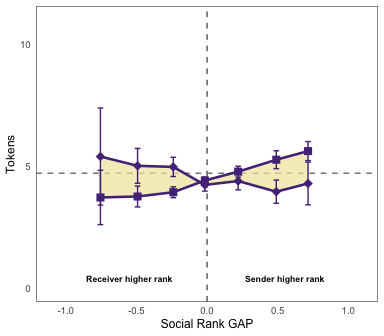

In [ ]:
tokens_non_friends

# The reusable plotting function

The function below packages these same layers so that the relationship
group and color can be supplied as arguments.

In [ ]:
mean_tokens <- mean(dyads$tokens_sent)

# Reuse this plotting specification for any relationship group.
plot_tokens <- function(this_group, color, version = "Observed") {
  bins <- binned %>% filter(group == this_group, version == !!version)

  ggplot(bins, aes(x = median_gap)) +
    geom_vline(xintercept = 0, linetype = "dashed", color = "grey40") +
    geom_hline(yintercept = mean_tokens, linetype = "dashed", color = "grey50") +
    # yellow area between the two mean curves (the observed Cooperation GAP)
    geom_ribbon(aes(ymin = mean_reci, ymax = mean_sent), fill = "#F0E5A8", alpha = 0.7) +
    # sent: rhombi
    geom_line(aes(y = mean_sent), color = color, linewidth = 0.9) +
    geom_errorbar(aes(ymin = mean_sent - se_sent, ymax = mean_sent + se_sent),
                  color = color, width = 0.04) +
    geom_point(aes(y = mean_sent), color = color, shape = 18, size = 3) +
    # received: squares
    geom_line(aes(y = mean_reci), color = color, linewidth = 0.9) +
    geom_errorbar(aes(ymin = mean_reci - se_reci, ymax = mean_reci + se_reci),
                  color = color, width = 0.04) +
    geom_point(aes(y = mean_reci), color = color, shape = 15, size = 2.5) +
    annotate("text", x = c(-0.55, 0.55), y = 0.4, size = 2.3, fontface = "bold",
             label = c("Receiver higher rank", "Sender higher rank")) +
    scale_x_continuous(limits = c(-1.1, 1.1), breaks = seq(-1, 1, 0.5)) +
    scale_y_continuous(limits = c(0, 11), breaks = c(0, 5, 10)) +
    labs(x = "Social Rank GAP", y = "Tokens") +
    theme_paper(base_size = 9)
}

# Mutual friends

In [ ]:
tokens_mutual <- plot_tokens("Mutual", color_mutual)

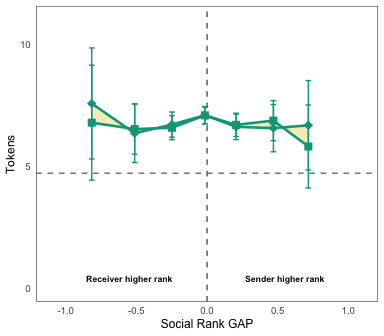

In [ ]:
tokens_mutual

# Sender-declared one-sided friendships

This group views each asymmetric pair from the child who nominated the
other. It differs from the folded heatmap in [Figure
3A](05_figure3a_exchange_patterns.ipynb), which combines both nomination
directions.

In [ ]:
tokens_asymmetric <- plot_tokens("Sender declares", color_asymmetric)

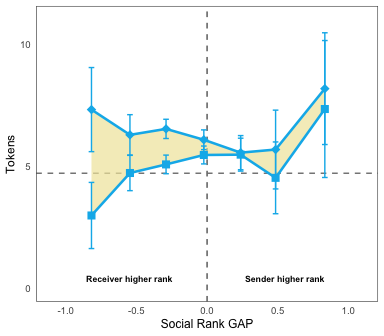

In [ ]:
tokens_asymmetric

The full summaries are saved by the command-line replication as
`output/tables/figure3_children_summary.csv` and
`output/tables/figure3_binned_means.csv`. [Figure
3C](07_figure3c_cooperation_gap.ipynb) uses the same construction for the
Cooperation GAP and explains how missing filtered values affect its
support.

# Session information

In [ ]:
sessionInfo()
## R version 4.3.2 (2023-10-31)
## Platform: aarch64-apple-darwin20 (64-bit)
## Running under: macOS 26.7.1
## 
## Matrix products: default
## BLAS:   /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRblas.0.dylib 
## LAPACK: /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRlapack.dylib;  LAPACK version 3.11.0
## 
## locale:
## [1] C.UTF-8/C.UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8
## 
## time zone: America/Santiago
## tzcode source: internal
## 
## attached base packages:
## [1] stats     graphics  grDevices utils     datasets  methods   base     
## 
## other attached packages:
##  [1] lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1   dplyr_1.1.4    
##  [5] purrr_1.0.4     readr_2.1.5     tidyr_1.3.1     tibble_3.2.1   
##  [9] ggplot2_3.5.2   tidyverse_2.0.0 here_1.0.1     
## 
## loaded via a namespace (and not attached):
##  [1] bit_4.6.0         gtable_0.3.6      jsonlite_2.0.0    crayon_1.5.3     
##  [5] compiler_4.3.2    tidyselect_1.2.1  parallel_4.3.2    scales_1.3.0     
##  [9] yaml_2.3.10       fastmap_1.2.0     R6_2.6.1          generics_0.1.3   
## [13] knitr_1.50        munsell_0.5.1     rprojroot_2.0.4   pillar_1.10.2    
## [17] tzdb_0.5.0        rlang_1.1.6       stringi_1.8.7     xfun_0.52        
## [21] bit64_4.6.0-1     timechange_0.3.0  cli_3.6.4         withr_3.0.2      
## [25] magrittr_2.0.3    digest_0.6.37     grid_4.3.2        vroom_1.6.5      
## [29] hms_1.1.3         lifecycle_1.0.4   vctrs_0.6.5       evaluate_1.0.3   
## [33] glue_1.8.0        farver_2.1.2      colorspace_2.1-1  rmarkdown_2.29   
## [37] tools_4.3.2       pkgconfig_2.0.3   htmltools_0.5.8.1

[Continue to Figure 3C: Cooperation
GAP](07_figure3c_cooperation_gap.ipynb).